In [9]:
import numpy,pandas,json,scipy
from matplotlib import pyplot
import matplotlib.patches as patches

from geochemistry_helpers import Sampling,GaussianProcess #type: ignore

# Set default dpi for saving
pyplot.rcParams['savefig.dpi'] = 600
# pyplot.rcParams.update({
#     "figure.facecolor":  (0.0, 0.0, 0.0, 0.0),
#     "axes.facecolor":    (0.0, 0.0, 0.0, 0.0),
#     "savefig.facecolor": (0.0, 0.0, 0.0, 0.0),
# })

# Age vs δ<sup>114</sup>Cd

In [10]:
# Load in d114Cd data
# Load each site
column_names = ["sample_number","depth","age","δ13C_org","TOC","[Cd]","CdEF","δ114Cd","δ114Cd_analytical_uncertainty"]
d114cd_by_site= {
    "svalbard": pandas.read_excel("./data/input/cadmium_data.xlsx",usecols="A:I",names=column_names).dropna(subset=["δ114Cd"]),
    "arctic": pandas.read_excel("./data/input/cadmium_data.xlsx",usecols="K:S",names=column_names).dropna(subset=["δ114Cd"]),
    "northsea": pandas.read_excel("./data/input/cadmium_data.xlsx",usecols="U:AC",names=column_names).dropna(subset=["δ114Cd"]),
    "kheu": pandas.read_excel("./data/input/cadmium_data.xlsx",usecols="AI:AQ",names=column_names).dropna(subset=["δ114Cd"])
}

# Assign uncertainties (can add a/multiply by a value to increase to account for non-analytical uncertainties)
d114cd_by_site["svalbard"]["δ114Cd_uncertainty"] = d114cd_by_site["svalbard"]["δ114Cd_analytical_uncertainty"]*1.0
d114cd_by_site["arctic"]["δ114Cd_uncertainty"] = d114cd_by_site["arctic"]["δ114Cd_analytical_uncertainty"]*1.0
d114cd_by_site["northsea"]["δ114Cd_uncertainty"] = d114cd_by_site["northsea"]["δ114Cd_analytical_uncertainty"]*1.0
d114cd_by_site["kheu"]["δ114Cd_uncertainty"] = d114cd_by_site["kheu"]["δ114Cd_analytical_uncertainty"]*1.0

# Add site to each dataframe
d114cd_by_site["svalbard"]["site"] = "svalbard"
d114cd_by_site["arctic"]["site"] = "arctic"
d114cd_by_site["northsea"]["site"] = "northsea"
d114cd_by_site["kheu"]["site"] = "kheu"


# Turn into distributions
cdca_bins = numpy.linspace(-1,1,1000)

# Load in GPs
d114cd_gp = GaussianProcess().fromJSON("./data/output/d114cd_gp.json")

# Load in prior_results
with open("./data/output/invert_organic_prior_results.json","r") as file:
    prior_results = json.load(file)

# Load in posterior_results
with open("./data/output/invert_organic_posterior_results.json","r") as file:
    posterior_results = json.load(file)

# Load in metrics
prior_metrics = pandas.read_excel("./data/output/invert_organic_prior_metrics.xlsx")
posterior_metrics = pandas.read_excel("./data/output/invert_organic_posterior_metrics.xlsx")

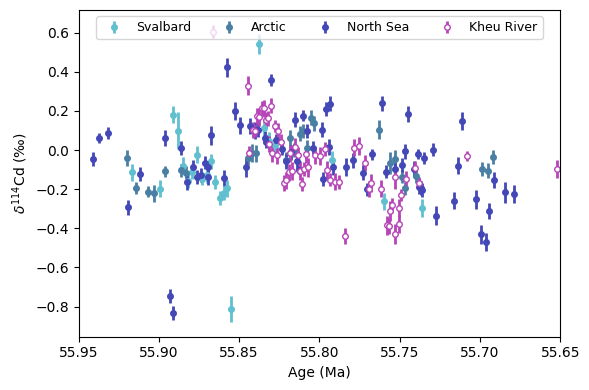

In [15]:
# Plot Data
figure,axis = pyplot.subplots(nrows=1,sharex=True,figsize=(6,4))
axes= [axis]

common_attributes = {"fmt":'o',
                     "zorder":0,
                     "markersize":4,
                     "linewidth":2}
handle_0 = axes[0].errorbar(d114cd_by_site["svalbard"]["age"],d114cd_by_site["svalbard"]["δ114Cd"],yerr=d114cd_by_site["svalbard"]["δ114Cd_uncertainty"],color="#60c0cf",ecolor="#60c0cf",**common_attributes)
handle_1 = axes[0].errorbar(d114cd_by_site["arctic"]["age"],d114cd_by_site["arctic"]["δ114Cd"],yerr=d114cd_by_site["arctic"]["δ114Cd_uncertainty"],color="#4a7fa4",ecolor="#4a7fa4",**common_attributes)
handle_2 = axes[0].errorbar(d114cd_by_site["northsea"]["age"],d114cd_by_site["northsea"]["δ114Cd"],yerr=d114cd_by_site["northsea"]["δ114Cd_uncertainty"],color="#4448b7",ecolor="#4448b7",**common_attributes)
handle_3 = axes[0].errorbar(d114cd_by_site["kheu"]["age"],d114cd_by_site["kheu"]["δ114Cd"],yerr=d114cd_by_site["kheu"]["δ114Cd_uncertainty"],markerfacecolor="#ffffff",markeredgecolor="#b744b7",ecolor="#b744b7",**common_attributes)

axes[0].legend([handle_0,handle_1,handle_2,handle_3],["Svalbard","Arctic","North Sea","Kheu River"],ncols=4,loc="upper center",fontsize=9)

axes[0].set_xlim((55.95,55.65))

# Add labels
axes[0].set_xlabel("Age (Ma)")
axes[0].set_ylabel("$\\delta^{114}$Cd (‰)")


figure.tight_layout()
pyplot.show()
# figure.savefig("./figures/cadmium_data.png",transparent=True)


# With GP

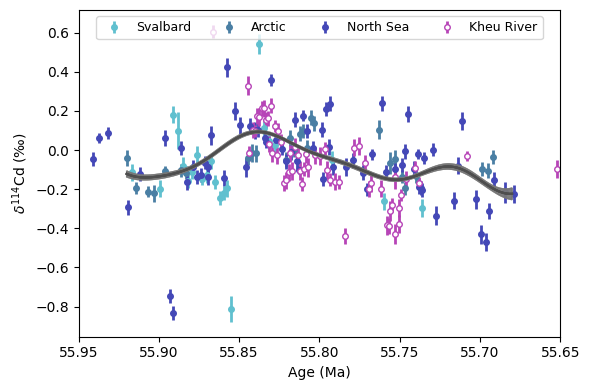

In [19]:
figure

d114cd_gp.plotMean(group=-1,color="#4e4e4e",axis=axes[0])
d114cd_gp.plotArea(group=-1,color="#777777",alpha=0.5,set_axes=False,axis=axes[0])


figure.tight_layout()
# figure.savefig("./figures/cadmium_data_gp.png",transparent=True)

figure